# Tugas PBL - Klasifikasi URL Berbahaya dengan JST (ANN)

Notebook ini membangun JST menggunakan Keras untuk mengklasifikasikan URL ke dalam 7 kelas: **benign, defacement, exploit, legitimate, malware, phishing, spam**.

Representasi input:

1. URL diubah menjadi karakter n-gram TF-IDF (3-5 karakter, maksimal 75.000 fitur).
2. TF-IDF diringkas dengan Truncated SVD menjadi 256 dimensi.
3. Hasil SVD distandarisasi dengan StandardScaler.

Eksperimen yang dilakukan, mengikuti pola Tugas MNIST:

1. Baseline: 2 hidden layer dengan 128 dan 64 neuron, aktivasi ReLU.
2. Mengubah jumlah neuron menjadi 256 dan 128.
3. Menambahkan satu hidden layer lagi (128-64-32).
4. Membandingkan aktivasi Sigmoid dan ReLU pada konfigurasi baseline.

Semua konfigurasi memakai split yang sama dari `MURL_Split.csv`, 10 epoch, batch 256, dan `class_weight="balanced"` karena distribusi kelas sangat tidak seimbang (benign 426.432 baris, exploit 243 baris).

**Cara menjalankan di Google Colab:**

1. Upload `Malicious URL Detection.csv` dan `MURL_Split.csv` ke `/content`.
2. Jalankan semua sel dari atas ke bawah.
3. Unduh notebook hasil run, lalu bagian analisis akan diisi berdasarkan output aktual.

Perkiraan waktu di Colab CPU: 10-25 menit. Sebagian besar waktu dipakai untuk TF-IDF dan SVD.


## 1. Import Library dan Konfigurasi


In [1]:
import gc
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

from IPython.display import display
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
EPOCHS = 10
BATCH_SIZE = 256
N_COMPONENTS = 256

CLASSES = [
    "benign",
    "defacement",
    "exploit",
    "legitimate",
    "malware",
    "phishing",
    "spam",
]

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)


TensorFlow: 2.21.0
NumPy: 2.4.6
Pandas: 2.2.3


## 2. Load Dataset dan Split

Dataset dibaca sesuai urutan aslinya. `MURL_Split.csv` berisi `row_id` yang sama dengan nomor baris CSV dataset, sehingga split ditempel berdasarkan urutan baris, bukan berdasarkan `merge`.

Split ini adalah split domain/IP-disjoint dari paket PBL: seluruh domain terdaftar beserta subdomainnya berada pada satu partisi. Validasi ini penting agar tidak ada host yang sama muncul di train dan test.

Pemeriksaan yang dilakukan:

- jumlah baris 783.705;
- `row_id` berurutan dari 0 sampai 783.704;
- hanya ada split `train`, `validation`, dan `test`;
- tujuh kelas muncul di setiap partisi;
- tidak ada URL yang memiliki label berbeda.


In [2]:
DATA_CANDIDATES = [
    Path("Malicious URL Detection.csv"),
    Path("/content/Malicious URL Detection.csv"),
]
SPLIT_CANDIDATES = [
    Path("MURL_Split.csv"),
    Path("/content/MURL_Split.csv"),
]


def locate_file(candidates, description):
    for candidate in candidates:
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(
        f"{description} tidak ditemukan. Upload file ke /content lalu jalankan ulang sel ini."
    )


data_path = locate_file(DATA_CANDIDATES, "Malicious URL Detection.csv")
split_path = locate_file(SPLIT_CANDIDATES, "MURL_Split.csv")

raw = pd.read_csv(data_path, dtype=str, keep_default_na=False)
split_frame = pd.read_csv(split_path)

assert raw.columns.tolist() == ["url", "type"], raw.columns.tolist()
assert split_frame.columns.tolist() == ["row_id", "split"], split_frame.columns.tolist()
assert len(raw) == len(split_frame) == 783705
assert np.array_equal(split_frame["row_id"].to_numpy(), np.arange(len(split_frame)))

df = pd.DataFrame({
    "url": raw["url"].str.strip(),
    "label": raw["type"].str.strip().str.lower(),
    "split": split_frame["split"].str.strip().str.lower(),
})

assert df["url"].ne("").all()
assert df["split"].isin(["train", "validation", "test"]).all()
assert set(df["label"].unique()) == set(CLASSES)
assert df.groupby("url")["label"].nunique().max() == 1

split_sizes = df["split"].value_counts().to_dict()
assert split_sizes == {"train": 548592, "validation": 117559, "test": 117554}, split_sizes

class_split = pd.crosstab(df["label"], df["split"]).reindex(
    index=CLASSES, columns=["train", "validation", "test"]
)
assert class_split.to_numpy().sum() == len(df)
assert (class_split > 0).all().all()

display(class_split)
display(df["split"].value_counts().to_frame("rows"))
print("Dataset:", data_path)
print("Split   :", split_path)
print(f"Total baris: {len(df):,}")
print(f"Duplikat URL: {int(df['url'].duplicated().sum()):,}")


split,train,validation,test
label,,,
benign,298498,63965,63969
defacement,66674,14295,14294
exploit,170,37,36
legitimate,4066,871,872
malware,16517,3541,3534
phishing,160738,34438,34437
spam,1929,412,412


,rows
split,
train,548592
validation,117559
test,117554


Dataset: Malicious URL Detection.csv
Split   : MURL_Split.csv
Total baris: 783,705
Duplikat URL: 3


## 3. Preprocessing - TF-IDF dan SVD

TF-IDF dan SVD hanya di-fit pada data train. Validation dan test hanya di-transform, sehingga kosakata, IDF, komponen SVD, dan statistik scaler tidak melihat data evaluasi.

Parameter TF-IDF mengikuti baseline PBL:

- analyzer karakter, n-gram 3-5;
- `min_df=2`;
- maksimal 75.000 fitur;
- `sublinear_tf=True`;
- normalisasi L2.

SVD meringkas 75.000 fitur menjadi 256 angka per URL. StandardScaler kemudian menyetarakan skala setiap komponen agar training ANN lebih stabil.


In [3]:
train_mask = df["split"].eq("train").to_numpy()
validation_mask = df["split"].eq("validation").to_numpy()
test_mask = df["split"].eq("test").to_numpy()

X_train_url = df.loc[train_mask, "url"]
X_validation_url = df.loc[validation_mask, "url"]
X_test_url = df.loc[test_mask, "url"]

label_to_int = {label: index for index, label in enumerate(CLASSES)}
y_train_int = df.loc[train_mask, "label"].map(label_to_int).to_numpy()
y_validation_int = df.loc[validation_mask, "label"].map(label_to_int).to_numpy()
y_test_int = df.loc[test_mask, "label"].map(label_to_int).to_numpy()

assert len(X_train_url) == 548592
assert len(X_validation_url) == 117559
assert len(X_test_url) == 117554
print("Ukuran data:", X_train_url.shape, X_validation_url.shape, X_test_url.shape)

vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    lowercase=False,
    min_df=2,
    max_features=75000,
    sublinear_tf=True,
    norm="l2",
    dtype=np.float32,
)

start = time.perf_counter()
X_train_tfidf = vectorizer.fit_transform(X_train_url)
X_validation_tfidf = vectorizer.transform(X_validation_url)
X_test_tfidf = vectorizer.transform(X_test_url)
tfidf_seconds = time.perf_counter() - start

print(f"TF-IDF selesai dalam {tfidf_seconds:.1f} s")
print("Jumlah fitur TF-IDF:", X_train_tfidf.shape[1])
print("Bentuk TF-IDF train/validation/test:",
      X_train_tfidf.shape, X_validation_tfidf.shape, X_test_tfidf.shape)

svd = TruncatedSVD(
    n_components=N_COMPONENTS,
    algorithm="randomized",
    n_iter=5,
    random_state=SEED,
)

start = time.perf_counter()
X_train_svd = svd.fit_transform(X_train_tfidf).astype(np.float32)
X_validation_svd = svd.transform(X_validation_tfidf).astype(np.float32)
X_test_svd = svd.transform(X_test_tfidf).astype(np.float32)
svd_seconds = time.perf_counter() - start

explained_variance = float(svd.explained_variance_ratio_.sum())
print(f"SVD selesai dalam {svd_seconds:.1f} s")
print(f"Explained variance ratio total ({N_COMPONENTS} komponen): {explained_variance:.4f}")
print("Bentuk SVD train/validation/test:",
      X_train_svd.shape, X_validation_svd.shape, X_test_svd.shape)

del X_train_tfidf, X_validation_tfidf, X_test_tfidf
gc.collect()

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_svd).astype(np.float32)
X_validation = scaler.transform(X_validation_svd).astype(np.float32)
X_test = scaler.transform(X_test_svd).astype(np.float32)

del X_train_svd, X_validation_svd, X_test_svd
gc.collect()

print("Bentuk akhir:", X_train.shape, X_validation.shape, X_test.shape)
print("Rentang nilai train:", float(X_train.min()), "sampai", float(X_train.max()))


Ukuran data: (548592,) (117559,) (117554,)
TF-IDF selesai dalam 156.3 s
Jumlah fitur TF-IDF: 75000
Bentuk TF-IDF train/validation/test: (548592, 75000) (117559, 75000) (117554, 75000)
SVD selesai dalam 215.3 s
Explained variance ratio total (256 komponen): 0.2485
Bentuk SVD train/validation/test: (548592, 256) (117559, 256) (117554, 256)
Bentuk akhir: (548592, 256) (117559, 256) (117554, 256)
Rentang nilai train: -15.815332412719727 sampai 25.77532958984375


## 4. Fungsi Membangun Model

Model menerima daftar jumlah neuron hidden layer sehingga jumlah layer dan ukuran layer dapat divariasikan. Output layer memakai 7 neuron dengan softmax.


In [4]:
def build_model(hidden_layers=(128, 64), activation="relu"):
    layers = [tf.keras.Input(shape=(N_COMPONENTS,), name="fitur_svd")]

    for index, units in enumerate(hidden_layers, start=1):
        layers.append(
            tf.keras.layers.Dense(units, activation=activation, name=f"hidden_{index}")
        )

    layers.append(tf.keras.layers.Dense(len(CLASSES), activation="softmax", name="output"))
    model = tf.keras.Sequential(layers)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    return model


## 5. Fungsi Training dan Evaluasi

Seed diatur ulang sebelum setiap model dibuat agar perbandingan antar konfigurasi adil. Class weight dihitung dari data train saja.

Metrik yang dihitung pada data test:

- accuracy;
- balanced accuracy;
- macro F1;
- weighted F1;
- classification report per kelas.


In [5]:
weight_values = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASSES)),
    y=y_train_int,
)
class_weight = {index: float(weight) for index, weight in enumerate(weight_values)}

display(pd.DataFrame({"kelas": CLASSES, "class_weight": weight_values}).round(4))


def run_experiment(name, hidden_layers, activation):
    np.random.seed(SEED)
    tf.keras.utils.set_random_seed(SEED)

    model = build_model(hidden_layers, activation)

    start = time.perf_counter()
    history = model.fit(
        X_train,
        y_train_int,
        validation_data=(X_validation, y_validation_int),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        class_weight=class_weight,
        verbose=0,
    )
    training_time = time.perf_counter() - start

    test_loss, test_accuracy = model.evaluate(X_test, y_test_int, verbose=0)
    probabilities = model.predict(X_test, batch_size=1024, verbose=0)
    predictions = np.argmax(probabilities, axis=1)

    metrics = {
        "accuracy": float(accuracy_score(y_test_int, predictions)),
        "balanced_accuracy": float(balanced_accuracy_score(y_test_int, predictions)),
        "macro_f1": float(f1_score(y_test_int, predictions, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_test_int, predictions, average="weighted", zero_division=0)),
    }

    report = classification_report(
        y_test_int,
        predictions,
        labels=np.arange(len(CLASSES)),
        target_names=CLASSES,
        output_dict=True,
        zero_division=0,
    )

    return {
        "name": name,
        "hidden_layers": hidden_layers,
        "activation": activation,
        "history": history.history,
        "test_loss": float(test_loss),
        "test_accuracy": float(test_accuracy),
        "metrics": metrics,
        "report": report,
        "predictions": predictions,
        "probabilities": probabilities,
        "training_time": training_time,
        "parameters": int(model.count_params()),
        "model": model,
    }


,kelas,class_weight
0,benign,0.2625
1,defacement,1.1754
2,exploit,461.0017
3,legitimate,19.2745
4,malware,4.7448
5,phishing,0.4876
6,spam,40.6274


## 6. Menjalankan Eksperimen

Empat konfigurasi diuji dengan data, seed, jumlah epoch, batch size, dan class weight yang sama.


In [6]:
configs = [
    ("Baseline 128-64 ReLU", (128, 64), "relu"),
    ("Neuron 256-128 ReLU", (256, 128), "relu"),
    ("Tambah Layer 128-64-32 ReLU", (128, 64, 32), "relu"),
    ("Baseline 128-64 Sigmoid", (128, 64), "sigmoid"),
]

results = []

for name, hidden_layers, activation in configs:
    result = run_experiment(name, hidden_layers, activation)
    results.append(result)

    print(f"{name}:")
    print(f"  test accuracy      = {result['metrics']['accuracy']:.4f}")
    print(f"  balanced accuracy  = {result['metrics']['balanced_accuracy']:.4f}")
    print(f"  macro F1           = {result['metrics']['macro_f1']:.4f}")
    print(f"  weighted F1        = {result['metrics']['weighted_f1']:.4f}")
    print(f"  test loss          = {result['test_loss']:.4f}")
    print(f"  waktu training     = {result['training_time']:.2f} s")
    print(f"  jumlah parameter   = {result['parameters']:,}")


Baseline 128-64 ReLU:
  test accuracy      = 0.6621
  balanced accuracy  = 0.6382
  macro F1           = 0.4131
  weighted F1        = 0.7044
  test loss          = 0.8790
  waktu training     = 110.54 s
  jumlah parameter   = 41,607
Neuron 256-128 ReLU:
  test accuracy      = 0.6765
  balanced accuracy  = 0.6800
  macro F1           = 0.4502
  weighted F1        = 0.7209
  test loss          = 0.9347
  waktu training     = 174.41 s
  jumlah parameter   = 99,591
Tambah Layer 128-64-32 ReLU:
  test accuracy      = 0.6384
  balanced accuracy  = 0.6900
  macro F1           = 0.4213
  weighted F1        = 0.6907
  test loss          = 0.9475
  waktu training     = 134.70 s
  jumlah parameter   = 43,463
Baseline 128-64 Sigmoid:
  test accuracy      = 0.6573
  balanced accuracy  = 0.6609
  macro F1           = 0.4246
  weighted F1        = 0.7068
  test loss          = 0.8952
  waktu training     = 125.67 s
  jumlah parameter   = 41,607


## 7. Tabel Perbandingan


In [7]:
tabel = pd.DataFrame([
    {
        "Konfigurasi": result["name"],
        "Hidden Layers": "-".join(str(units) for units in result["hidden_layers"]),
        "Aktivasi": result["activation"].capitalize(),
        "Test Accuracy": round(result["metrics"]["accuracy"], 4),
        "Balanced Accuracy": round(result["metrics"]["balanced_accuracy"], 4),
        "Macro F1": round(result["metrics"]["macro_f1"], 4),
        "Weighted F1": round(result["metrics"]["weighted_f1"], 4),
        "Test Loss": round(result["test_loss"], 4),
        "Waktu (s)": round(result["training_time"], 2),
        "Parameter": result["parameters"],
    }
    for result in results
])

display(tabel)

f1_per_class = pd.DataFrame({
    result["name"]: {
        label: result["report"][label]["f1-score"] for label in CLASSES
    }
    for result in results
}).T

display(f1_per_class.round(4))


,Konfigurasi,Hidden Layers,Aktivasi,Test Accuracy,Balanced Accuracy,Macro F1,Weighted F1,Test Loss,Waktu (s),Parameter
0,Baseline 128-64 ReLU,128-64,Relu,0.6621,0.6382,0.4131,0.7044,0.8790,110.54,41607
1,Neuron 256-128 ReLU,256-128,Relu,0.6765,0.6800,0.4502,0.7209,0.9347,174.41,99591
2,Tambah Layer 128-64-32 ReLU,128-64-32,Relu,0.6384,0.6900,0.4213,0.6907,0.9475,134.70,43463
3,Baseline 128-64 Sigmoid,128-64,Sigmoid,0.6573,0.6609,0.4246,0.7068,0.8952,125.67,41607


,benign,defacement,exploit,legitimate,malware,phishing,spam
Baseline 128-64 ReLU,0.7338,0.8168,0.0631,0.1186,0.4532,0.6523,0.0540
Neuron 256-128 ReLU,0.7387,0.8215,0.0586,0.1261,0.6856,0.6734,0.0470
Tambah Layer 128-64-32 ReLU,0.7144,0.7799,0.0743,0.0965,0.5859,0.6438,0.0546
Baseline 128-64 Sigmoid,0.7290,0.8137,0.0534,0.1081,0.5581,0.6601,0.0499


## 8. Grafik Training

Grafik menampilkan validation loss dan validation accuracy setiap epoch. Validation set berasal dari `MURL_Split.csv` dan tidak dipakai untuk memperbarui bobot.


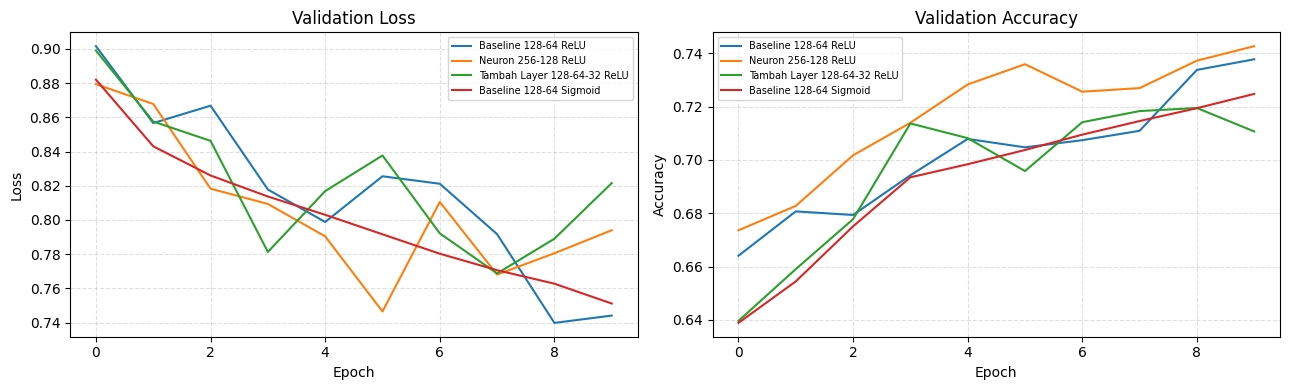

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for result in results:
    axes[0].plot(result["history"]["val_loss"], label=result["name"])
    axes[1].plot(result["history"]["val_accuracy"], label=result["name"])

axes[0].set_title("Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=7)
axes[0].grid(True, ls="--", alpha=0.4)

axes[1].set_title("Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend(fontsize=7)
axes[1].grid(True, ls="--", alpha=0.4)

plt.tight_layout()
plt.show()


## 9. Confusion Matrix dan Contoh Prediksi

Model terbaik dipilih berdasarkan macro F1 pada data test, karena accuracy dapat didominasi kelas benign yang berjumlah jauh lebih besar. Confusion matrix ditampilkan dalam jumlah baris dan proporsi per kelas aktual.


Model terbaik berdasarkan macro F1: Neuron 256-128 ReLU (macro F1 0.4502, accuracy 0.6765)


,precision,recall,f1-score,support
benign,0.8982,0.6274,0.7387,63969.0
defacement,0.8147,0.8285,0.8215,14294.0
exploit,0.0306,0.7222,0.0586,36.0
legitimate,0.0695,0.6812,0.1261,872.0
malware,0.6376,0.7414,0.6856,3534.0
phishing,0.6483,0.7005,0.6734,34437.0
spam,0.0248,0.4587,0.0470,412.0
macro avg,0.4462,0.6800,0.4502,117554.0
weighted avg,0.7975,0.6765,0.7209,117554.0


,benign,defacement,exploit,legitimate,malware,phishing,spam
benign,40131,1569,70,4580,386,11464,5769
defacement,952,11843,29,87,46,1111,226
exploit,0,0,26,0,9,1,0
legitimate,94,12,0,594,3,132,37
malware,65,18,429,67,2620,327,8
phishing,3314,1092,297,3175,1041,24122,1396
spam,122,3,0,44,4,50,189


,benign,defacement,exploit,legitimate,malware,phishing,spam
benign,0.627,0.025,0.001,0.072,0.006,0.179,0.090
defacement,0.067,0.829,0.002,0.006,0.003,0.078,0.016
exploit,0.000,0.000,0.722,0.000,0.250,0.028,0.000
legitimate,0.108,0.014,0.000,0.681,0.003,0.151,0.042
malware,0.018,0.005,0.121,0.019,0.741,0.093,0.002
phishing,0.096,0.032,0.009,0.092,0.030,0.700,0.041
spam,0.296,0.007,0.000,0.107,0.010,0.121,0.459


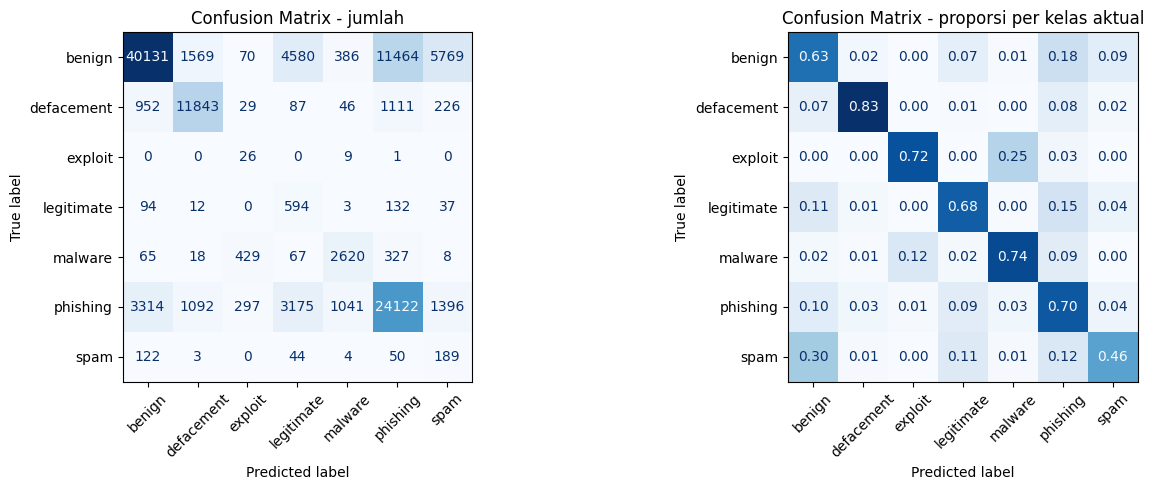

,url,aktual,prediksi,confidence,benar
0,tutorgig.com/ed/expo_67,benign,spam,0.8641,False
1,yapikur.com.tr,phishing,spam,0.2842,False
2,homepages.rootsweb.ancestry.com/~yvonne/garris...,benign,phishing,0.6230,False
3,bessels.com/projecten/industrie/0651-wincanton...,defacement,benign,0.8449,False
4,amazon.com/what-were-once-vices-habits/dp/b000...,benign,spam,0.8953,False
5,charlesdentalgroup.com/cdg/sacramento_dr/index...,benign,defacement,0.4819,False
6,csdi-dlstatic.tennoio.com/un/bundle_solimba_ma...,malware,phishing,0.8432,False
7,oac.cdlib.org/view?docid=bk0005s657s;naan=2872...,benign,phishing,0.6591,False
8,oldies.com/product-view/4937d.html,benign,phishing,0.4287,False
9,cs.colorado.edu/~tor/saclass-2001,phishing,benign,0.3568,False


Jumlah salah prediksi pada test: 38,029 dari 117,554


In [10]:
best = max(results, key=lambda result: result["metrics"]["macro_f1"])
print(
    "Model terbaik berdasarkan macro F1:",
    best["name"],
    f"(macro F1 {best['metrics']['macro_f1']:.4f}, "
    f"accuracy {best['metrics']['accuracy']:.4f})",
)

report_table = pd.DataFrame(best["report"]).T
display(report_table.loc[CLASSES + ["macro avg", "weighted avg"]].round(4))

cm = confusion_matrix(y_test_int, best["predictions"], labels=np.arange(len(CLASSES)))
cm_frame = pd.DataFrame(cm, index=CLASSES, columns=CLASSES)
cm_normalized = pd.DataFrame(
    cm / cm.sum(axis=1, keepdims=True),
    index=CLASSES,
    columns=CLASSES,
)

display(cm_frame)
display(cm_normalized.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(
    ax=axes[0], cmap="Blues", colorbar=False, xticks_rotation=45, values_format="d"
)
ConfusionMatrixDisplay(cm_normalized.to_numpy(), display_labels=CLASSES).plot(
    ax=axes[1], cmap="Blues", colorbar=False, xticks_rotation=45, values_format=".2f"
)
axes[0].set_title("Confusion Matrix - jumlah")
axes[1].set_title("Confusion Matrix - proporsi per kelas aktual")
plt.tight_layout()
plt.show()

test_urls = df.loc[test_mask, "url"].to_numpy()
correct_index = np.flatnonzero(best["predictions"] == y_test_int)
wrong_index = np.flatnonzero(best["predictions"] != y_test_int)
rng = np.random.default_rng(SEED)

selected = np.concatenate([
    rng.choice(wrong_index, size=min(10, len(wrong_index)), replace=False),
    rng.choice(correct_index, size=min(10, len(correct_index)), replace=False),
])

examples = pd.DataFrame({
    "url": test_urls[selected],
    "aktual": [CLASSES[index] for index in y_test_int[selected]],
    "prediksi": [CLASSES[index] for index in best["predictions"][selected]],
    "confidence": best["probabilities"][selected].max(axis=1).round(4),
})
examples["benar"] = examples["aktual"].eq(examples["prediksi"])
display(examples)
print(f"Jumlah salah prediksi pada test: {len(wrong_index):,} dari {len(y_test_int):,}")

## 10. Analisis Hasil

Seluruh angka di bagian ini diambil dari output aktual notebook. Nilai yang ditandai *turunan* dihitung dari confusion matrix atau tabel yang tercetak.

### 10.1 Konfigurasi run

| Item | Nilai |
|---|---|
| Dataset | 783.705 baris; 7 kelas |
| Split | 548.592 train / 117.559 validation / 117.554 test |
| TF-IDF | char n-gram 3-5; 75.000 fitur; 156,3 s |
| SVD | 256 komponen; 215,3 s; explained variance 0,2485 |
| Scaler | StandardScaler, fit pada train |
| Model | Dense ANN, output softmax 7 kelas |
| Class weight | balanced, dihitung dari train |
| Training | 10 epoch; batch 256; Adam learning rate 0,001 |
| Total waktu | preprocessing 371,6 s + training 545,3 s = 916,9 s (sekitar 15,3 menit) |
| Lingkungan | TensorFlow 2.21.0; NumPy 2.4.6; Pandas 2.2.3 |
| Model terbaik | Neuron 256-128 ReLU; macro F1 0,4502 |

Explained variance SVD hanya **0,2485**. Artinya 256 komponen menyimpan sekitar 24,85% variasi TF-IDF; sekitar 75,15% variasi hilang sebelum masuk ANN.

### 10.2 Hasil utama

| Konfigurasi | Test Accuracy | Balanced Accuracy | Macro F1 | Weighted F1 | Test Loss | Waktu (s) | Parameter |
|---|---:|---:|---:|---:|---:|---:|---:|
| Baseline 128-64 ReLU | 0,6621 | 0,6382 | 0,4131 | 0,7044 | 0,8790 | 110,54 | 41.607 |
| **Neuron 256-128 ReLU** | **0,6765** | **0,6800** | **0,4502** | **0,7209** | 0,9347 | 174,41 | 99.591 |
| Tambah Layer 128-64-32 ReLU | 0,6384 | **0,6900** | 0,4213 | 0,6907 | 0,9475 | 134,70 | 43.463 |
| Baseline 128-64 Sigmoid | 0,6573 | 0,6609 | 0,4246 | 0,7068 | 0,8952 | 125,67 | 41.607 |

F1 per kelas:

| Konfigurasi | benign | defacement | exploit | legitimate | malware | phishing | spam |
|---|---:|---:|---:|---:|---:|---:|---:|
| Baseline 128-64 ReLU | 0,7338 | 0,8168 | 0,0631 | 0,1186 | 0,4532 | 0,6523 | 0,0540 |
| Neuron 256-128 ReLU | 0,7387 | 0,8215 | 0,0586 | 0,1261 | 0,6856 | 0,6734 | 0,0470 |
| Tambah Layer 128-64-32 ReLU | 0,7144 | 0,7799 | 0,0743 | 0,0965 | 0,5859 | 0,6438 | 0,0546 |
| Baseline 128-64 Sigmoid | 0,7290 | 0,8137 | 0,0534 | 0,1081 | 0,5581 | 0,6601 | 0,0499 |

### 10.3 Efek arsitektur

1. **256-128 ReLU adalah model terbaik.** Dibandingkan baseline 128-64 ReLU, accuracy naik **1,44 poin persentase**, balanced accuracy naik **4,18 pp**, macro F1 naik **3,71 pp**, dan weighted F1 naik **1,65 pp**. Biayanya adalah **57.984 parameter tambahan** (2,394x) dan waktu training **1,578x** lebih lama (+63,87 s).
2. **Menambah satu hidden layer tidak sepadan.** Konfigurasi 128-64-32 memang memiliki balanced accuracy tertinggi, yaitu **0,6900** (+5,18 pp dari baseline), tetapi accuracy turun **2,37 pp** menjadi **0,6384**, macro F1 hanya naik **0,82 pp**, dan weighted F1 turun **1,37 pp**. Layer tambahan mendorong prediksi ke kelas minoritas sehingga recall rata-rata naik, tetapi presisi jatuh.
3. **Sigmoid praktis seri dengan ReLU pada konfigurasi yang sama.** Accuracy Sigmoid **0,6573**, hanya **0,48 pp** di bawah baseline ReLU. Macro F1 justru **1,15 pp** lebih tinggi dan balanced accuracy **2,27 pp** lebih tinggi. Selisih ini kecil dan berasal dari satu seed, jadi belum dapat disimpulkan Sigmoid lebih baik.
4. **Lebar lebih berguna daripada kedalaman pada dataset ini.** Menambah neuron dari 128-64 menjadi 256-128 menaikkan accuracy dan macro F1, sedangkan menambah layer 32 neuron justru menurunkan accuracy. Kapasitas tambahan lebih efektif dipakai untuk melebarkan layer daripada menambah layer.
5. **Test loss tidak sejalan dengan macro F1.** Baseline ReLU memiliki test loss terendah (**0,8790**) tetapi macro F1 terendah (**0,4131**). Model 256-128 memiliki loss lebih tinggi (**0,9347**) tetapi macro F1 tertinggi. Test loss dihitung tanpa class weight, sehingga tidak mengukur keseimbangan kelas.

### 10.4 Class weight dan kelas minoritas

Class weight dihitung dari data train:

| Kelas | Baris train | Class weight |
|---|---:|---:|
| benign | 298.498 | 0,2625 |
| defacement | 66.674 | 1,1754 |
| exploit | 170 | **461,0017** |
| legitimate | 4.066 | 19,2745 |
| malware | 16.517 | 4,7448 |
| phishing | 160.738 | 0,4876 |
| spam | 1.929 | 40,6274 |

Kinerja model terbaik (256-128 ReLU) per kelas:

| Kelas | Support test | Prediksi* | TP | FP* | Precision | Recall | F1 |
|---|---:|---:|---:|---:|---:|---:|---:|
| benign | 63.969 | 44.678 | 40.131 | 4.547 | 0,8982 | 0,6274 | 0,7387 |
| defacement | 14.294 | 14.537 | 11.843 | 2.694 | 0,8147 | 0,8285 | 0,8215 |
| exploit | 36 | 851 | 26 | 825 | 0,0306 | 0,7222 | 0,0586 |
| legitimate | 872 | 8.547 | 594 | 7.953 | 0,0695 | 0,6812 | 0,1261 |
| malware | 3.534 | 4.109 | 2.620 | 1.489 | 0,6376 | 0,7414 | 0,6856 |
| phishing | 34.437 | 37.207 | 24.122 | 13.085 | 0,6483 | 0,7005 | 0,6734 |
| spam | 412 | 7.625 | 189 | 7.436 | 0,0248 | 0,4587 | 0,0470 |

\*Prediksi dan FP adalah nilai turunan dari confusion matrix.

1. **Class weight ekstrem membuat kelas langka diprediksi jauh lebih sering daripada jumlah sebenarnya.** Exploit diprediksi **23,64x** lebih banyak (851 vs 36), spam **18,51x** (7.625 vs 412), dan legitimate **9,80x** (8.547 vs 872). Ini sumber utama kehancuran precision.
2. **Exploit menangkap sebagian besar contoh nyata, tetapi hampir tidak dapat dipercaya.** Recall **26/36 = 72,22%**, dengan Wilson 95% sekitar **0,560-0,842**. Namun precision hanya **3,06%**: dari 851 prediksi exploit, 825 adalah false positive. Sebanyak **429** false positive berasal dari malware dan **297** dari phishing.
3. **Legitimate dan spam juga dibanjiri false positive.** Legitimate memiliki recall **68,12%**, tetapi precision **6,95%** dan **7.953 FP**. Spam memiliki recall **45,87%**, tetapi precision **2,48%** dan **7.436 FP**. Untuk sistem keamanan, angka ini tidak dapat diterima.
4. **Benign justru menjadi korban underprediction.** Benign hanya diprediksi **44.678** kali untuk **63.969** baris, dengan recall **62,74%**. Sebanyak **11.464** benign diprediksi phishing, **5.769** diprediksi spam, dan **4.580** diprediksi legitimate. Bobot benign 0,2625 membuat model terlalu agresif menebak kelas lain.
5. **Macro F1 jauh di bawah balanced accuracy.** Macro F1 **0,4502**, sedangkan balanced accuracy **0,6800**. Class weight berhasil menaikkan recall rata-rata, tetapi presisi kelas minoritas hancur. Macro F1 menghukum kegagalan presisi itu; balanced accuracy tidak.
6. **Kelas yang relatif kuat hanya defacement dan benign.** Defacement F1 **0,8215** dengan recall **82,85%**; benign F1 **0,7387** meskipun recallnya turun. Malware F1 **0,6856**, phishing **0,6734**. Tiga kelas terburuk adalah exploit (**0,0586**), spam (**0,0470**), dan legitimate (**0,1261**).

Kesalahan terbesar pada confusion matrix:

| Aktual | Prediksi | Jumlah |
|---|---|---:|
| benign | phishing | 11.464 |
| benign | spam | 5.769 |
| benign | legitimate | 4.580 |
| phishing | benign | 3.314 |
| phishing | legitimate | 3.175 |
| phishing | spam | 1.396 |
| defacement | phishing | 1.111 |
| phishing | defacement | 1.092 |
| phishing | malware | 1.041 |
| defacement | benign | 952 |
| malware | exploit | 429 |

Contoh prediksi pada bagian 9 sengaja memilih **10 baris salah dan 10 baris benar**, sehingga akurasi 50% pada tabel contoh bukan estimasi performa. Contoh tetap berguna untuk melihat jenis kesalahan dan keyakinan model. Beberapa kesalahan memiliki confidence tinggi: benign diprediksi spam dengan confidence **0,8953**, defacement diprediksi benign **0,8449**, dan malware diprediksi phishing **0,8432**. Sebaliknya, sebagian besar prediksi yang benar memiliki confidence tinggi, misalnya defacement **1,0000** dan phishing **0,9998**. Model tidak hanya salah, tetapi pada sebagian kasus salah dengan keyakinan tinggi.

### 10.5 Grafik training

Nilai berikut dibaca secara aproximatif dari grafik validation:

- **256-128 ReLU** mencapai validation accuracy tertinggi, sekitar **0,742** pada epoch 9. Validation loss terendah sekitar **0,746** pada epoch 5, lalu naik lagi ke sekitar **0,79** pada epoch 9. Accuracy masih naik, tetapi loss memburuk: model menjadi lebih percaya diri pada prediksi yang salah.
- **Baseline 128-64 ReLU** berakhir dengan validation loss terendah, sekitar **0,742**, dan validation accuracy sekitar **0,737**. Kurvanya paling stabil di antara model ReLU.
- **128-64-32 ReLU** tidak stabil. Validation loss turun ke sekitar **0,782** pada epoch 3, lalu naik ke sekitar **0,821**. Validation accuracy memuncak sekitar **0,737** pada epoch 5, lalu turun ke sekitar **0,709**.
- **Sigmoid** bergerak paling halus: validation accuracy sekitar **0,725** dan validation loss sekitar **0,75** pada epoch terakhir.

Temuan ini menunjukkan **early stopping di sekitar epoch 5-6** mungkin menguntungkan model 256-128 dan mencegah memburuknya model 128-64-32. Notebook memakai 10 epoch tetap tanpa early stopping.

### 10.6 Perbandingan dengan baseline dan PBL

| Model | Preprocessing | Test Accuracy | Balanced Accuracy | Macro F1 | Weighted F1 |
|---|---|---:|---:|---:|---:|
| Majority baseline | - | 0,5442 | 0,1429 | 0,1007 | 0,3835 |
| **ANN 256-128 (notebook ini)** | TF-IDF 75k ke SVD 256 | **0,6765** | 0,6800 | 0,4502 | 0,7209 |
| SVM 54 fitur (PBL 02) | 54 fitur URL | 0,5992 | 0,4821 | 0,3638 | 0,6288 |
| SVM TF-IDF (PBL 01) | TF-IDF 75k penuh | **0,8358** | **0,6850** | **0,7064** | **0,8393** |

1. **ANN jauh di atas majority baseline.** Accuracy naik **13,23 pp**, balanced accuracy **53,71 pp**, dan macro F1 **34,95 pp**. Model benar-benar belajar sinyal, bukan sekadar menebak kelas mayoritas.
2. **ANN mengalahkan SVM dengan 54 fitur.** Accuracy **+7,73 pp**, balanced accuracy **+19,79 pp**, dan macro F1 **+8,64 pp**. Fitur struktur URL saja jelas tidak cukup; representasi karakter n-gram menambah informasi besar.
3. **ANN masih kalah dari SVM TF-IDF penuh.** Accuracy turun **15,93 pp**, macro F1 turun **25,62 pp**, dan weighted F1 turun **11,84 pp**. Namun balanced accuracy hanya berbeda **0,50 pp** (0,6800 vs 0,6850).
4. **Selisih balanced accuracy kecil, selisih macro F1 besar.** Artinya ANN menangkap kelas minoritas secara rata-rata hampir sama sering dengan SVM, tetapi presisinya jauh lebih buruk. SVM exploit memiliki precision 0,9600 dan F1 0,7869; ANN exploit precision 0,0306 dan F1 0,0586.
5. **SVD adalah kandidat utama penyebab gap.** Hanya **24,85%** variasi TF-IDF yang dipertahankan, sedangkan SVM memakai seluruh 75.000 fitur. Perbandingan ini bukan apple-to-apple karena preprocessing berbeda; namun hasilnya menunjukkan representasi lebih menentukan daripada jenis classifier.
6. **Dibanding Tugas MNIST, dataset ini jauh lebih sulit.** Tugas MNIST mencapai accuracy 0,9556-0,9728 dengan 10 kelas seimbang dan input piksel. Notebook ini mencapai 0,6384-0,6765 dengan 7 kelas sangat tidak seimbang, split domain-disjoint, dan representasi SVD. Pola yang sama tetap muncul: model lebih lebar menang, layer tambahan tidak selalu menolong, dan perbedaan ReLU vs Sigmoid kecil.

### 10.7 Validasi, test, dan stabilitas

1. **Ada jarak antara validation dan test untuk model terbaik.** Validation accuracy 256-128 sekitar **0,74**, sedangkan test accuracy **0,6765**; jaraknya sekitar **6-7 pp** (aproximatif dari grafik). Sebagian berasal dari overfitting setelah epoch 5, sebagian dari komposisi kelas yang berbeda.
2. **Validation loss naik setelah epoch 5, tetapi validation accuracy masih naik.** Pola ini menunjukkan model semakin percaya diri, termasuk pada prediksi yang salah. Test loss 256-128 (**0,9347**) juga lebih tinggi daripada baseline (**0,8790**).
3. **Baseline masih membaik sampai epoch 9.** Baseline belum tentu sudah konvergen; model 256-128 justru mulai memburuk lebih awal. Jumlah epoch yang sama belum tentu optimal untuk semua arsitektur.
4. **Satu seed, satu split.** Tidak ada repeated run atau cross-validation. Perbedaan di bawah 1-2 pp, seperti Sigmoid vs ReLU baseline, tidak dapat dianggap nyata. Kenaikan macro F1 3,71 pp pada 256-128 lebih besar, tetapi tetap perlu diuji dengan seed lain.

### 10.8 Limitasi

1. **Tidak ada cross-validation atau repeated seed.** Semua kesimpulan berasal dari satu run per konfigurasi.
2. **Test exploit hanya 36 baris.** Satu kesalahan menggeser recall sekitar 2,78 pp; interval Wilson 95% untuk recall 26/36 adalah sekitar 0,560-0,842.
3. **SVD hanya menyimpan 24,85% variasi TF-IDF.** Sinyal langka seperti pola exploit dan spam berpotensi hilang sebelum masuk ANN.
4. **Class weight balanced tidak dituning.** Bobot exploit 461x dan spam 40,6x sangat ekstrem; belum diuji bobot lebih ringan, `class_weight=None`, atau kalibrasi threshold.
5. **Tidak ada hyperparameter search.** Learning rate, batch size, jumlah epoch, jumlah neuron, dan jumlah komponen SVD ditetapkan manual.
6. **Split domain/IP-disjoint mencegah kebocoran host, tetapi bukan bukti generalisasi ke ancaman baru.** Dataset tidak memiliki timestamp, source, atau campaign ID.
7. **Label benign dan legitimate dapat tumpang tindih.** Precision legitimate 6,95% sebagian dapat berasal dari definisi label yang ambigu, bukan hanya kesalahan model.
8. **Accuracy dan weighted F1 didominasi benign dan phishing.** Macro F1 dan balanced accuracy harus menjadi metrik utama untuk dataset ini.

### 10.9 Kesimpulan

1. **Model terbaik adalah 256-128 ReLU** dengan test accuracy **0,6765**, balanced accuracy **0,6800**, macro F1 **0,4502**, dan weighted F1 **0,7209**.
2. **Menambah lebar layer membantu; menambah layer tidak.** 256-128 menaikkan macro F1 3,71 pp, sedangkan 128-64-32 hanya menaikkan 0,82 pp sambil menurunkan accuracy 2,37 pp.
3. **Sigmoid dan ReLU hampir setara pada konfigurasi baseline.** Perbedaan accuracy hanya 0,48 pp; tidak ada bukti ReLU lebih unggul pada run ini.
4. **Class weight balanced menaikkan recall kelas langka, tetapi menghancurkan precision.** Exploit, legitimate, dan spam diprediksi 9,8-23,6x lebih sering daripada jumlah sebenarnya. Macro F1 0,4502 jauh di bawah balanced accuracy 0,6800.
5. **ANN dengan SVD masih kalah dari SVM TF-IDF penuh.** Accuracy 0,6765 vs 0,8358 dan macro F1 0,4502 vs 0,7064. Balanced accuracy hampir sama (0,6800 vs 0,6850), sehingga masalah utama ANN adalah presisi kelas minoritas dan kehilangan informasi akibat SVD.
6. **ANN tetap lebih baik daripada majority baseline dan SVM 54 fitur.** Representasi karakter n-gram memberi sinyal yang jelas, tetapi pemampatan SVD dan pembobotan kelas perlu diperbaiki sebelum model layak dipakai.

### 10.10 Rekomendasi lanjutan

| Prioritas | Tindakan | Alasan |
|---|---|---|
| 1 | Kalibrasi threshold atau turunkan class weight | 825 FP exploit, 7.953 FP legitimate, dan 7.436 FP spam |
| 2 | Tambah komponen SVD atau pakai TF-IDF penuh | Explained variance hanya 24,85%; SVM TF-IDF jauh lebih kuat |
| 3 | Early stopping dan repeated seed | 256-128 memburuk setelah epoch 5; hasil satu seed belum stabil |
| 4 | Bandingkan `class_weight=None`, `sqrt`, dan balanced | Ukur trade-off accuracy vs macro F1 secara eksplisit |
| 5 | Analisis n-gram per kelas | Pahami penyebab benign diprediksi phishing dan spam |
| 6 | Laporkan macro F1 dan balanced accuracy | Accuracy dan weighted F1 didominasi benign dan phishing |
